### __Anna Kaczyńska, Kamila Mosińska__
## PROJECT 4: Stochastic analysis of an aquifer tracer test
-----

### ABSTRACT


### INTRODUCTION

----------------

## Part 1

At each time step, the particle can move according to three option: move to the right with probability $p_+$ and displacement $+ \Delta x$, move to the left with probability $p_-$ and displacement $- \Delta x$ and stay with probability $1 - p_+ - p_-$. 

So $Y$ is a random variable with the following possible values:
$$
Y=
\begin{cases}
+\Delta x & \text{with probability }p_+\\
-\Delta x & \text{with probability }p_-\\
0 & \text{with probability }1-p_+-p_-
\end{cases}
$$

The mean displacement in one step is calculated as follows:
$$
\mathbb{E}[Y] = (+ \Delta x) \cdot p_+ + (- \Delta  x) \cdot p_- + 0 \cdot (1 - p_+ - p_-) = (p_+ - p_-)\Delta x.
$$

Since $t = n\Delta t$, the mean velocity of the particle is given by:
$$
v = \frac{s}{t} = \frac{n \cdot \mathbb{E}[Y]}{n\Delta t} = \frac{(p_+ - p_-)\Delta x}{\Delta t}.
$$

To be able to determine the equation for D, we start with calculating the variance of one step:
$$
Var[Y] = \mathbb{E}[Y^2] - \mathbb{E}[Y]^2 = [(\Delta x)^2 p_+ + (- \Delta x)^2 p_-] - [(p_+ - p_-)\Delta x]^2 = (p_+ + p_-)\Delta x - (p_+ - p_-)^2 \Delta x^2 = [p_+ + p_- - (p_+ - p_-)^2] \Delta x^2.
$$

Since steps are independent, the variance after n steps is equal to:
$$
Var(X_n) = nVar(Y),
$$
and
$$
Var(X_n) = n[p_+ + p_- - (p_+ - p_-)^2] \Delta x^2 = \frac{t}{\Delta t}[p_+ + p_- - (p_+ - p_-)^2] \Delta x^2 .
$$

For an instantaneous release at x=0, the analytical solution is a Gaussian distribution:
$$
C(x,t)=\frac{M}{\sqrt{4\pi Dt}}
\exp\left(-\frac{x^2}{4Dt}\right).
$$

When we compare the exponential part with the standard form of a normal distribution, we get:
$$
\sigma^2 = 2Dt.
$$

Since variance for normal distribution is equal to $\sigma^2$, we get:
$$
Var(X(t)) = 2Dt.
$$

After some transformations, we get:
$$
D = \frac{Var(X(t))}{2t} = \frac{\frac{t}{\Delta t}[p_+ + p_- - (p_+ - p_-)^2] \Delta x^2}{2t} = \frac{[p_+ + p_- - (p_+ - p_-)^2] \Delta x^2 }{2 \Delta t}.
$$

In [31]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, probplot
import pandas as pd
from scipy.optimize import least_squares

In [32]:
rng = np.random.default_rng()

In [33]:
class Solver:
    def __init__(self, x0, t0, v=0.5, D=1, alpha_L=2, lamb=0.002, M=1000, L1=50, L2=500):
        self.x0 = x0
        self.t0 = t0
        self.v = v
        self.D = D
        self.alpha_L = alpha_L
        self.lamb = lamb
        self.M = M
        self.L1 = L1
        self.L2 = L2

    def random_walk_1d(self, dt, number_of_steps, N = 20000, decay=True):
        p_decay = 1 - np.exp(-self.lamb*dt)

        trajectories = np.zeros((N, number_of_steps + 1))
        trajectories[:, 0] = self.x0
        alive = np.ones(N, dtype=bool)

        # checkpoint
        alive_count = np.zeros(number_of_steps + 1, dtype=int)
        alive_count[0] = N

        for i in range(number_of_steps):
            random_steps = np.random.normal(0, 1, N)
            trajectories[alive, i+1] = (trajectories[alive, i] + self.v * dt + np.sqrt(2 * self.D * dt) * random_steps[alive])

            if decay:
                decay_events = np.random.random(N) < p_decay
                alive = alive & ~decay_events
            
            trajectories[~alive, i+1] = np.nan

            alive_count[i+1] = np.sum(alive)
            
        return trajectories, alive_count

    def concentration_profile(self, trajectories, N, dt, time_points, bins=100, x_range=(0, 500)):
        profiles = {}

        bin_edges = np.linspace(x_range[0], x_range[1], bins+1)
        bin_centers = (bin_edges[:-1]  + bin_edges[1:]) / 2
        bin_width = bin_edges[1] - bin_edges[0]

        for t in time_points:
            step = int(t/dt)
            positions = trajectories[:, step]
            positions = positions[~np.isnan(positions)]

            counts, _ = np.histogram(positions, bins=bin_edges)

            C = (self.M/N) * counts / bin_width
            profiles[t] = C

        return bin_centers, profiles

    def concentration_ananlytical(self, x, t):
        C = (self.M / np.sqrt(4*np.pi*self.D*t)) * np.exp(-((x - self.v*t)**2)/(4*self.D*t) - self.lamb*t)
        return C

    def first_arrival_times(self, trajectories, dt):
        L1 = self.L1

        previous = trajectories[:, :-1]
        current = trajectories[:, 1:]

        crossed = (previous < L1) & (current > L1)
        arrived = np.any(crossed, axis=1)
        first_cross = np.argmax(crossed, axis=1)

        arrival_times = np.full(trajectories.shape[0], np.nan)
        arrival_times[arrived] = (first_cross[arrived] + 1) * dt

        return arrival_times

    def first_arrival_analytical(self, t):
        L1 = self.L1
        f = L1/(np.sqrt(4*np.pi*self.D*t**3)) * np.exp(-((L1-self.v*t)**2)/(4*self.D*t))
        return f

    def concentration_tracer(self, L1, t, theta):
            f1, f2, v1, v2, v3, alpha_L = theta
            f3 = 1-f1-f2
            f = [f1, f2, f3]
            v = [v1, v2, v3]
    
            C = 0
            for i in range(3):
                sum = (f[i] * self.M / np.sqrt(4 *np.pi * alpha_L * v[i] *t) * np.exp(-(L1 - v[i] * t)**2 / (4 * alpha_L * v[i] * t)))
                C += sum
    
            return C
    
    def misfit(self, L1, t_data, theta, sigma, C_obs):

        C_tracer = np.array([self.concentration_tracer(L1, t, theta) for t in t_data])
        J = (1 / (2 * sigma**2)) * np.sum((C_tracer - C_obs)**2)
        
        return J
    
    def local_opt(self, L1, t_data, theta_init, sigma, C_obs):

        def residuals(x):
            a, b, v1, v2, v3, alpha_L = x
            f1 = a
            f2 = (1 - a) * b

            theta = [f1, f2, v1, v2, v3, alpha_L]
            C_tracer = np.array([
                self.concentration_tracer(L1, t, theta)
                for t in t_data
            ])

            return (C_tracer - C_obs) / sigma

        f1, f2, v1, v2, v3, alpha_L = theta_init
        a = f1
        b = f2 / (1 - f1) if f1 < 1 else 0
        x0 = [a, b, v1, v2, v3, alpha_L]
        lower = [0, 0, 0.1, 0.1, 0.1, 0.05]
        upper = [1, 1, 2, 2, 2, 5]

        opt = least_squares(residuals,x0,bounds=(lower, upper))
        a, b, v1, v2, v3, alpha_L = opt.x
        f1 = a
        f2 = (1-a)*b
        theta_opt = [f1,f2,v1,v2,v3,alpha_L]

        return theta_opt
    
    def multi_start(self, L1, t_data, sigma, C_obs):
        results = []
        for i in range(40):
            f1 = rng.uniform(0, 1)
            f2 = rng.uniform(0, 1-f1)
            v1 = rng.uniform(0.1, 2)
            v2 = rng.uniform(0.1, 2)
            v3 = rng.uniform(0.1, 2)
            alpha_L = rng.uniform(0.05, 5)
            theta_init = [f1, f2, v1, v2, v3, alpha_L]

            theta_opt = self.local_opt(L1, t_data, theta_init, sigma, C_obs)
            J = self.misfit(L1, t_data, theta_opt, sigma, C_obs)
            results.append((theta_opt, J))

        return results

    def simulated_annealing(self, f, x0, bounds, T0=1000, T_min=0.5, tau=0.95, steps_per_T=100, proposal_width=0.1):
        
        x = np.array(x0, dtype=float)
        f_x = f(x)
        lower, upper = np.array(bounds[0]), np.array(bounds[1])
        best_x = x.copy()
        best_f = f_x
        T = T0
        k = 0
        proposal_width = 0.1 * (upper - lower)
        trace_x = [x.copy()]
        trace_f = [f_x]

        while T>T_min:
            for _ in range(steps_per_T):
                sigma = proposal_width * np.sqrt(T / T0)
                x_new = x + rng.normal(0, sigma)

                if np.any(x_new < lower) or np.any(x_new > upper):
                    trace_x.append(x.copy())
                    trace_f.append(f_x)
                    continue

                f_new = f(x_new)
                dE = f_new - f_x

                if dE < 0 or rng.random() < np.exp(-dE/T):
                    x, f_x = x_new, f_new

                if f_x < best_f:
                    best_x, best_f = x.copy(), f_x 

                trace_x.append(x.copy())
                trace_f.append(f_x)

            k += 1
            T = T0 * np.exp(-k/tau)

        return {
        "best_x": best_x,
        "best_f": best_f,
        "trace_x": np.array(trace_x),
        "trace_f": np.array(trace_f)
    }

In [34]:
def plot_particle_position(trajectories, dt, times=[40, 120, 300]):

    plt.figure(figsize=(10, 5))

    colors = ['tab:blue', 'tab:orange', 'tab:green']

    for t, color in zip(times, colors):

        step = int(t / dt)
        positions = trajectories[:, step]

        positions = positions[~np.isnan(positions)]
        y = np.random.uniform(0, 1, len(positions))

        plt.scatter(
            positions,
            y,
            s=2,
            alpha=0.4,
            color=color,
            label=f't = {t} days'
        )

    plt.axvline(50, color='red', linestyle='--')

    plt.xlabel('x [m]')
    plt.legend()
    plt.tight_layout()
    plt.show()

Initial number of particles: 20000
Surviving particles: 10791
Decayed particles: 9209
Percentage decayed: 46.05%


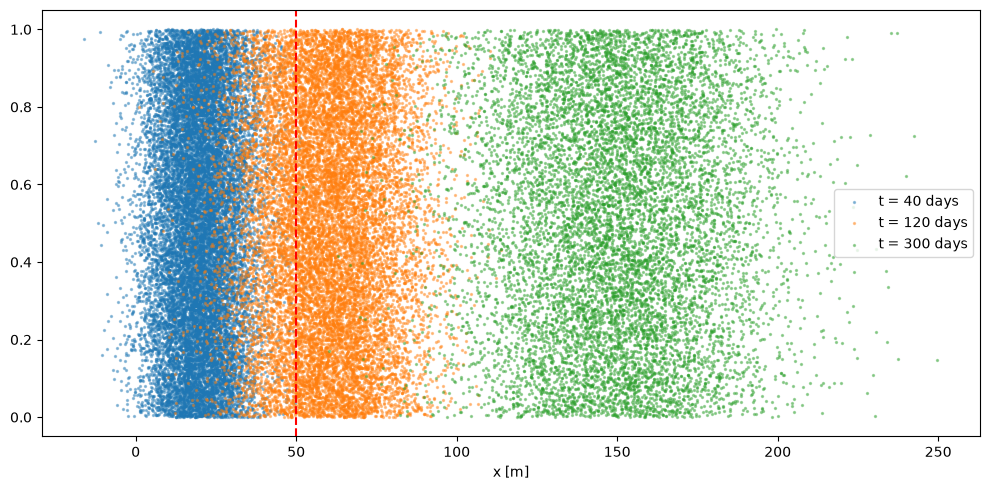

In [35]:
dt = 0.5
number_of_steps = 600  # 300 days
N = 20000

solver = Solver(x0=0, t0=0)

trajectories, alive_count = solver.random_walk_1d(
    dt=dt,
    number_of_steps=number_of_steps,
    N=N
)

print(f"Initial number of particles: {N}")
print(f"Surviving particles: {alive_count[-1]}")
print(f"Decayed particles: {N - alive_count[-1]}")
print(f"Percentage decayed: {(N - alive_count[-1]) / N * 100:.2f}%")

plot_particle_position(trajectories, dt)

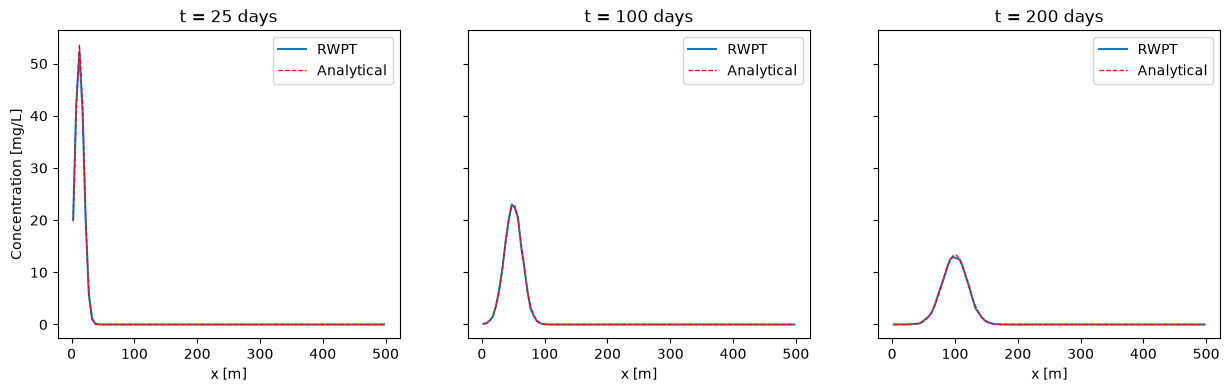

In [36]:
time_points = [25, 100, 200]

x, profiles = solver.concentration_profile(
    trajectories=trajectories,
    N=N,
    dt=dt,
    time_points=time_points,
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for ax, t in zip(axes,time_points):
    ax.plot(x, profiles[t], label="RWPT", color="tab:blue")

    C_analytical = solver.concentration_ananlytical(x, t)
    ax.plot(x, C_analytical, "--", linewidth=0.9, label="Analytical", color="red")

    ax.set_title(f"t = {t} days")
    ax.set_xlabel("x [m]")
    ax.legend()

axes[0].set_ylabel("Concentration [mg/L]")
plt.show()

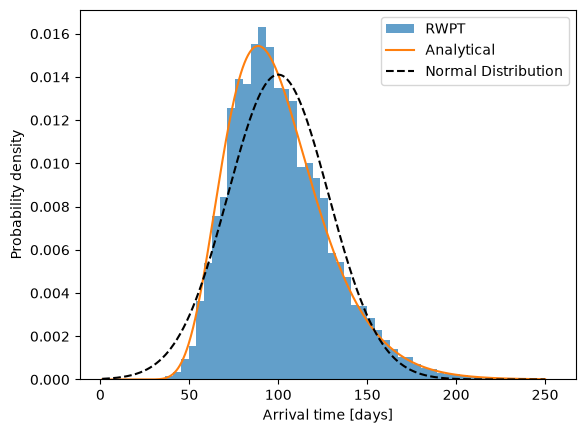

In [37]:
trajectories_no_decay, _ = solver.random_walk_1d(dt=0.5, number_of_steps=600, N=20000, decay=False)

arrival_times = solver.first_arrival_times(trajectories_no_decay, dt)
valid_arrivals = arrival_times[~np.isnan(arrival_times)]

t = np.linspace(1, 250, 1000)
f_analytical = solver.first_arrival_analytical(t)

mean = solver.L1 / solver.v
variance = 2 * solver.D * solver.L1 / solver.v**3
std = np.sqrt(variance)
normal_distribution = norm.pdf(t, mean, std)

plt.figure()
plt.hist(valid_arrivals, bins=50, density=True, alpha=0.7, label="RWPT")
plt.plot(t, f_analytical, label="Analytical")
plt.plot(t, normal_distribution, linestyle='--', color="black", label="Normal Distribution")
plt.xlabel("Arrival time [days]")
plt.ylabel("Probability density")
plt.legend()
plt.show()

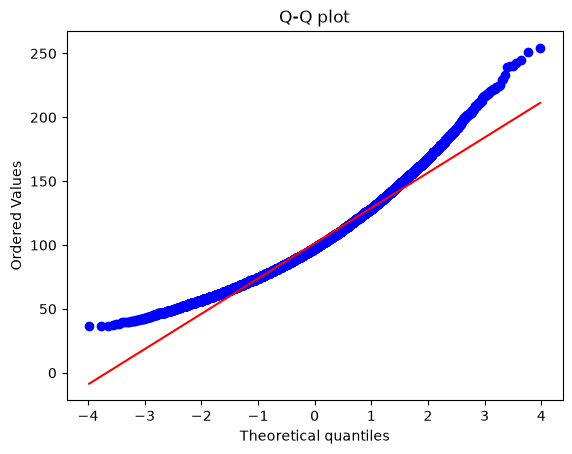

In [38]:
plt.figure()
probplot(valid_arrivals, dist="norm", plot=plt)
plt.title("Q-Q plot")
plt.show()

Based on the Q-Q plot above, we can say that arrival time does not follow normal distribution.

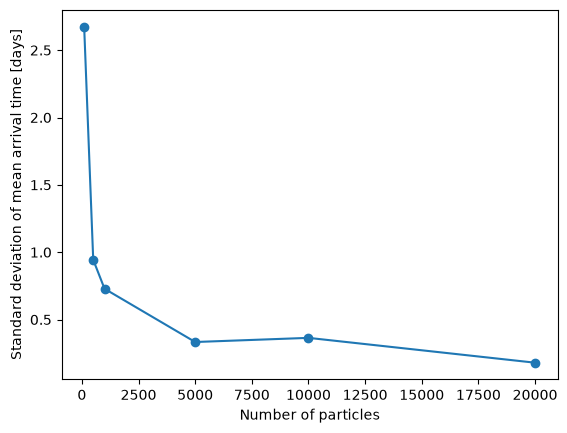

In [39]:
Ns = [100, 500, 1000, 5000, 10000, 20000]
repeats = 20
errors = []

for N in Ns:
    means = []
    for _ in range(repeats):
        traj, _ = solver.random_walk_1d(dt=0.5, number_of_steps=600, N=N, decay=False)
        arrivals = solver.first_arrival_times(traj, 0.5)
        means.append(np.nanmean(arrivals))
    errors.append(np.std(means))

plt.figure()
plt.plot(Ns, errors, "o-")
plt.xlabel("Number of particles")
plt.ylabel("Standard deviation of mean arrival time [days]")
plt.show()

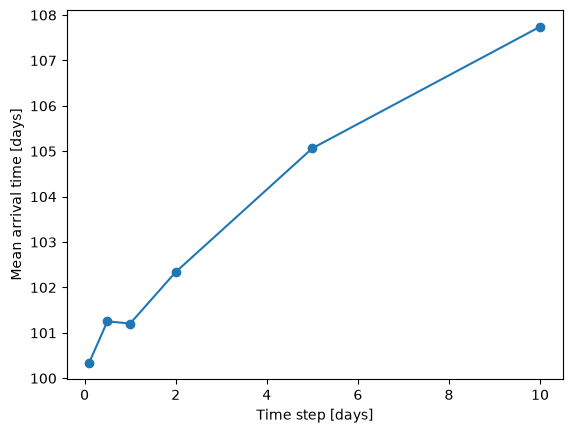

In [40]:
dts = np.array([0.1, 0.5, 1, 2, 5, 10])
N = 20000
mean_arrivals = []

for dt in dts:
    traj, _ = solver.random_walk_1d(dt=dt, number_of_steps=int(600/dt), N=N, decay=False)
    arrivals = solver.first_arrival_times(traj, dt)
    mean_arrivals.append(np.nanmean(arrivals))

plt.figure()
plt.plot(dts, mean_arrivals, "o-")
plt.xlabel("Time step [days]")
plt.ylabel("Mean arrival time [days]")
plt.show()

The mean arrival time is biased for large $\Delta t$ because the crossing condition compares the particle's positions at two consecutive time steps. Therefore, larger time steps result in less precise estimates of the arrival times. For large $N$, the statistical error becomes smaller, as it decreases approximately as $\frac{1}{\sqrt(N)}$, and the time-step bias becomes the dominant error.

### Discussion

RWPT is useful when the aquifer is heterogeneous, meaning that its properties vary in space, because particle movement can be adjusted depending on the local conditions. It is also a good choice when modelling sharp concentration fronts, as it avoids the numerical spreading that can occur in grid-based methods. However, RWPT can require a large number of particles to obtain accurate results, which increases computational cost. Grid-based methods can be faster and more efficient when a concentration field over the entire domain is needed. Therefore, RWPT is often preferable for complex problems where numerical dispersion should be minimized, while grid-based methods may be more suitable for simpler problems where computational efficiency is important.

## Part 2

The Eq. 2 from the project is:
$$
C(x,t)=\frac{M}{\sqrt{4\pi Dt}}
\exp\left(-\frac{(x-vt)^2}{4Dt} - \lambda t\right).
$$

After substituting $x=L_2$ and $t = L_2/v$, we get:
$$
C(L_2, L_2/v)=\frac{M}{\sqrt{4\pi D (\frac{L_2}{v})}}
\exp\left(-\frac{(L_2-v\frac{L_2}{v})^2}{4D\frac{L_2}{v}} - \lambda \frac{L_2}{v}\right) = \frac{M}{\sqrt{4\pi D (\frac{L_2}{v})}}
\exp\left(-\frac{\lambda L_2}{v}\right).
$$

We substitute $D=\alpha_L v$ and get:
$$
C_{peak} = \frac{M}{\sqrt{4\pi \alpha_L v (\frac{L_2}{v})}}
\exp\left(-\frac{\lambda L_2}{v}\right) = \frac{M}{\sqrt{4\pi \alpha_L L_2}}
\exp\left(-\frac{\lambda L_2}{v}\right)
$$

In [41]:
def sample_parameters(N):
    v = np.random.lognormal(mean=np.log(0.5), sigma=0.3, size=N)
    alpha_L = np.random.lognormal(mean=np.log(2), sigma=0.5, size=N)
    lamb = np.random.lognormal(mean=np.log(2*10**(-3)), sigma=0.3, size=N)
    return v, alpha_L, lamb

def calculate_peak_concentration(v, alpha_L, lamb, M, L2):
    C_peak = (M / np.sqrt(4 * np.pi * alpha_L * L2)) * np.exp(-lamb * L2 / v)
    return C_peak

In [42]:
N_values = [10**3, 10**4, 10**5, 10**6]
C_lim = 7.0

results = []
for N in N_values:

    v, alpha_L, lamb = sample_parameters(N)
    C_peak = calculate_peak_concentration(v, alpha_L, lamb, M=solver.M, L2=solver.L2)

    print(f"C_peak = {C_peak} for {N} samples")

C_peak = [1.17795446e+00 2.03369065e-01 2.38213166e+00 2.48270003e+00
 3.03880063e+00 1.66660010e+00 1.86112928e+00 3.98725397e+00
 7.75999650e-01 6.53406236e-01 2.58216853e+00 1.66324602e+00
 1.00514703e+00 2.58504816e+00 3.36264269e+00 2.02459061e+00
 1.56540061e+00 5.08308451e-01 3.27506314e-01 2.81729598e+00
 5.99797529e-01 9.63925916e-01 1.79306090e+00 3.21790372e+00
 2.15405377e+00 1.12026270e+00 2.57854420e-01 7.96204524e-01
 6.53220955e-01 1.83813300e+00 2.63421961e+00 5.40807373e-01
 1.68070335e+00 1.06637404e+00 1.30587437e+00 6.76365375e-01
 2.36861080e+00 9.89676430e-01 3.81942823e+00 1.14479896e+00
 3.71863900e-01 1.05635722e+00 7.29549294e-01 5.10134805e+00
 2.14147275e+00 1.18899726e+00 3.87076825e-01 7.82381425e-01
 1.45975228e+00 1.22609948e+00 2.05688041e+00 9.52838168e-01
 1.82938307e+00 1.33538153e+00 8.64139236e-01 4.16189715e-01
 7.02753490e-01 6.56667782e-01 3.03940366e+00 3.52037485e-01
 1.88537467e+00 9.89754939e-01 1.50130197e+00 5.40287726e+00
 8.00793134e-01

## Part 3

In [43]:
tracer_test = pd.read_csv("tracer_test.csv")
tracer_test.head()

,time_days,concentration_mg_per_L
0,5.0,6.1228
1,10.0,-7.6670
2,15.0,1.2543
3,20.0,-1.7033
4,25.0,-1.3577


### Local Optimization: Least-squares

In [55]:
# initiating the parameters needed to run the misfit function

L1 = 50
t_data = tracer_test["time_days"]
sigma = 3
C_obs = tracer_test["concentration_mg_per_L"]

solver = Solver(x0=0, t0=0)
# we call on the function multi_start, which computes J from 40 different starting points
results = solver.multi_start(L1, t_data, sigma, C_obs)

In [56]:
best_theta, best_J = min(results, key=lambda x: x[1])

f1, f2, v1, v2, v3, alpha_L = best_theta
f3 = 1 - f1 - f2

print(f"Global minimum misfit: J = {best_J:.6f}")

print("Best parameters:")
print(f"f1 = {f1:.4f}")
print(f"f2 = {f2:.4f}")
print(f"f3 = {f3:.4f}")
print(f"v1 = {v1:.4f}")
print(f"v2 = {v2:.4f}")
print(f"v3 = {v3:.4f}")
print(f"alpha_L = {alpha_L:.4f}")
print(f"Misfit = {best_J:.4f}")

Global minimum misfit: J = 29.780056
Best parameters:
f1 = 0.2967
f2 = 0.1993
f3 = 0.5040
v1 = 0.5904
v2 = 1.1154
v3 = 0.3018
alpha_L = 0.2996
Misfit = 29.7801


In [57]:
print("All 40 misfit values:")

min_runs = 0

for i, result in enumerate(results):
    if abs(result[1] - best_J) < 1e-5:
        min_runs +=1

    print(f"Run {i+1}: J = {result[1]:.6f}")

All 40 misfit values:
Run 1: J = 64.835989
Run 2: J = 537.194430
Run 3: J = 48.175181
Run 4: J = 112.351994
Run 5: J = 29.780056
Run 6: J = 29.780056
Run 7: J = 29.780056
Run 8: J = 58.067687
Run 9: J = 67.932281
Run 10: J = 29.780056
Run 11: J = 29.780056
Run 12: J = 537.194430
Run 13: J = 29.780056
Run 14: J = 29.780056
Run 15: J = 140.089357
Run 16: J = 67.932280
Run 17: J = 67.932280
Run 18: J = 29.780056
Run 19: J = 67.932281
Run 20: J = 29.780056
Run 21: J = 29.780056
Run 22: J = 29.780056
Run 23: J = 48.175181
Run 24: J = 29.780056
Run 25: J = 29.780056
Run 26: J = 48.175181
Run 27: J = 29.780056
Run 28: J = 29.780056
Run 29: J = 48.175181
Run 30: J = 29.780056
Run 31: J = 29.780056
Run 32: J = 67.932280
Run 33: J = 29.780056
Run 34: J = 29.780056
Run 35: J = 48.175181
Run 36: J = 29.780056
Run 37: J = 29.780056
Run 38: J = 29.780056
Run 39: J = 29.780056
Run 40: J = 128.663559


In [58]:
print("\nFraction of runs with minimalized J:", min_runs/ len(results))


Fraction of runs with minimalized J: 0.575


The misfit function $J$ has several minima as it contains three different flow paths, each with parameters $v_i$ and $f_i$, which interact with each other. It may be the case, that when fitting a particular data peak, different unique combinations of the parameters produce similar concentration values, resulting in several local minima.

Swapping the labels of the 3 flows wouldn't impact the predicted concentration values. The final concentration is a sum of all three flow paths, with their respective parameters, hence simply exchanging the labels does not impact the overall contribution of each of the flows in the solution.

In general, when fitting the models several times, the fraction of runs finding the minimal value was in the range 50-70%, where this particular run achieved 57.5% instances of finding the same lowest value.

In [59]:
local_theta, local_J = max(results, key=lambda x: x[1])

print(f"Local minimum misfit: J = {local_J:.6f}")

f1, f2, v1, v2, v3, alpha_L = local_theta
f3 = 1 - f1 - f2

print("Worst parameters:")
print(f"f1 = {f1:.4f}")
print(f"f2 = {f2:.4f}")
print(f"f3 = {f3:.4f}")
print(f"v1 = {v1:.4f}")
print(f"v2 = {v2:.4f}")
print(f"v3 = {v3:.4f}")
print(f"alpha_L = {alpha_L:.4f}")
print(f"Misfit = {local_J:.4f}")

Local minimum misfit: J = 537.194430
Worst parameters:
f1 = 0.3664
f2 = 0.4141
f3 = 0.2196
v1 = 1.1253
v2 = 0.5859
v3 = 2.0000
alpha_L = 0.6105
Misfit = 537.1944


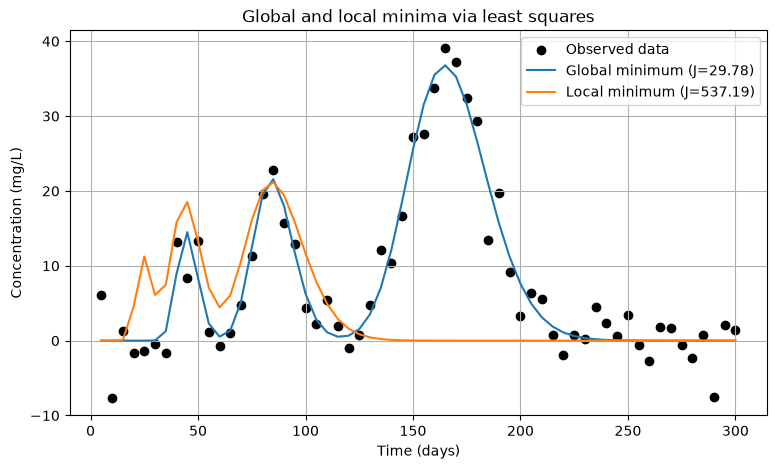

In [60]:
C_global = np.array([
    solver.concentration_tracer(L1, t, best_theta)
    for t in t_data
])

C_local = np.array([
    solver.concentration_tracer(L1, t, local_theta)
    for t in t_data
])

plt.figure(figsize=(9, 5))
plt.scatter(t_data, C_obs, color='black', label='Observed data')
plt.plot(t_data, C_global, label=f'Global minimum (J={best_J:.2f})')
plt.plot(t_data, C_local, label=f'Local minimum (J={local_J:.2f})')

plt.xlabel('Time (days)')
plt.ylabel('Concentration (mg/L)')
plt.title('Global and local minima via least squares')
plt.legend()
plt.grid()
plt.show()

Above is shown a comparison between our best and worst run, with minimized function $J$ being $J = 29.78$ at it's best and $J = 537.19$ at it's worst run. 

The worst run seemed to focus too much on the first two data peaks, completely neglecting the biggest peak on the right.

### Simulated Annealing

In [49]:
# initiating theta bounds and inital theta guesses needed for SA

lower = np.array([0, 0, 0.1, 0.1, 0.1, 0.05])
upper = np.array([1, 1, 2, 2, 2, 5])
bounds = (lower, upper)

a = rng.uniform(0, 1)
b = rng.uniform(0, 1)
v1 = rng.uniform(0.1, 2)
v2 = rng.uniform(0.1, 2)
v3 = rng.uniform(0.1, 2)
alpha_L = rng.uniform(0.05, 5)

theta_init = np.array([a, b, v1, v2, v3, alpha_L])

In [50]:
def objective_sa(x):
    a, b, v1, v2, v3, alpha_L = x
    f1 = a
    f2 = (1-a)*b
    theta = [f1, f2, v1, v2, v3, alpha_L]

    return solver.misfit(L1, t_data, theta, sigma, C_obs)

In [51]:
tau_values = [25, 50, 75, 100]
n_runs = 20
results = {}

absolute_best_f = np.inf
absolute_best_x = None
absolute_best_tau = None

for tau in tau_values:
    best_misfits = []

    for i in range(n_runs):

        theta_init = np.array([
            rng.uniform(0, 1),
            rng.uniform(0, 1),
            rng.uniform(0.1, 2),
            rng.uniform(0.1, 2),
            rng.uniform(0.1, 2),
            rng.uniform(0.05, 5)
        ])

        SA = solver.simulated_annealing(
            f=objective_sa,
            x0=theta_init,
            bounds=bounds,
            T0=1000,
            T_min=0.5,
            tau=tau,
            steps_per_T=20
        )

        best_misfits.append(SA["best_f"])

        if SA["best_f"] < absolute_best_f:

            absolute_best_f = SA["best_f"]
            absolute_best_x = SA["best_x"].copy()
            absolute_best_tau = tau

    results[tau] = best_misfits

    print(f"Tau = {tau}")
    print(f"Best misfit: {np.min(best_misfits):.4f}")
    print(f"Mean misfit: {np.mean(best_misfits):.4f}")
    print(f"Std misfit: {np.std(best_misfits):.4f}")
    print(f"\n")

print('-'*50)
print("BEST RUN:")

print("Best tau:", absolute_best_tau)
print("Best misfit:", absolute_best_f)

a, b, v1, v2, v3, alpha_L = absolute_best_x
f1 = a
f2 = (1-a)*b
f3 = (1-a)*(1-b)
theta_best = [f1, f2, v1, v2, v3, alpha_L]

print("\nBest parameters:")
print("f1:", f1)
print("f2:", f2)
print("f3:", f3)
print("Sum of fractions:", f1+f2+f3)
print("v1:", v1)
print("v2:", v2)
print("v3:", v3)
print("alpha_L:", alpha_L)

Tau = 25
Best misfit: 30.9196
Mean misfit: 108.5913
Std misfit: 67.2883


Tau = 50
Best misfit: 29.8699
Mean misfit: 77.6269
Std misfit: 59.6398


Tau = 75
Best misfit: 29.9106
Mean misfit: 57.4763
Std misfit: 35.3272


Tau = 100
Best misfit: 29.9306
Mean misfit: 52.4791
Std misfit: 38.8618


--------------------------------------------------
BEST RUN:
Best tau: 50
Best misfit: 29.86989688106492

Best parameters:
f1: 0.30450901616618437
f2: 0.19376859373767172
f3: 0.5017223900961439
Sum of fractions: 1.0
v1: 0.5902280039891992
v2: 1.1156483662293222
v3: 0.30187101867468624
alpha_L: 0.297790118204711


We ran the simulated annealing algorithm with 4 different $\tau$ values $\tau = [25,50,75,100]$, but also for each $\tau$ we run the algorithm 20 times. Our motivation was that one signle run initiated from random points might not be the best representation of the effect of the $\tau$ parameter on the data. Therefore we documented for all values of $\tau$, the smallest achieved $J$, the mean $J$ and the standard deviation of $J$ results for the particular $\tau$. 

From that, we observed that the average value of $J$ as well as the standard deviation of $J$ decreased with the increase of $\tau$. With the increase of $\tau$, the temperature decreased more gradually, which allowed the algorithm to run for a longer time, being able to explore more areas and potentially escape local minimas - which translated to smaller means and standard deviations of the results. With the rapid cooling of the temperature, for lower values of $\tau$, the results are less reliable since the algorithm runs for a shorter amount of time, being more likely to accept worse solutions overall.

In general, slower cooling of the system provides us with more stable solutions, where the probability of reaching a global minimum is higher, but we need to balance it with computational complexity to reach a good solution in finite time.

In [52]:
C_computed = np.array([solver.concentration_tracer(L1, t, theta_best) for t in t_data])
C_computed

array([4.48422720e-128, 1.47310557e-048, 1.90545581e-023, 6.31724176e-012,
       7.73295376e-006, 1.82669138e-002, 1.21589204e+000, 8.70909036e+000,
       1.41270235e+001, 8.10853419e+000, 2.19692146e+000, 5.05631006e-001,
       1.34699343e+000, 5.29280491e+000, 1.26855108e+001, 1.99634014e+001,
       2.22132561e+001, 1.85171337e+001, 1.21049105e+001, 6.43714701e+000,
       2.87358093e+000, 1.13223490e+000, 5.21871825e-001, 6.39590346e-001,
       1.51456139e+000, 3.49069235e+000, 6.98009408e+000, 1.21442842e+001,
       1.86272477e+001, 2.55042304e+001, 3.15163210e+001, 3.54895583e+001,
       3.67267839e+001, 3.51904793e+001, 3.14267345e+001, 2.63122233e+001,
       2.07623382e+001, 1.55128561e+001, 1.10212623e+001, 7.47376341e+000,
       4.85399741e+000, 3.02868568e+000, 1.82062546e+000, 1.05707363e+000,
       5.94177346e-001, 3.24021184e-001, 1.71758803e-001, 8.86593333e-002,
       4.46373374e-002, 2.19529157e-002, 1.05610428e-002, 4.97618306e-003,
       2.29918145e-003, 1

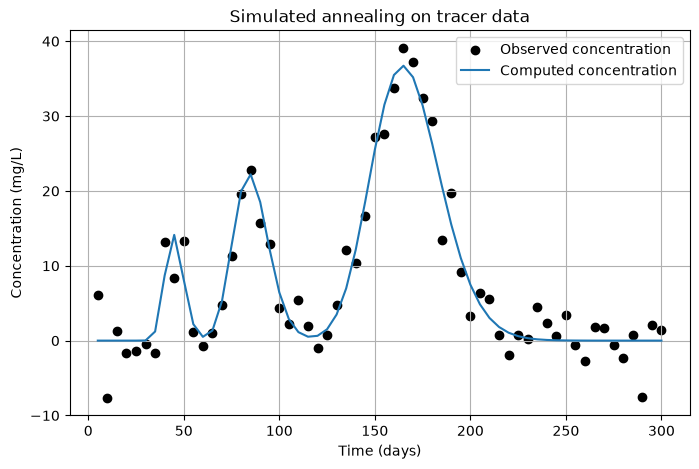

In [53]:
plt.figure(figsize=(8,5))
plt.scatter(t_data, C_obs, color = 'black', label="Observed concentration")
plt.plot(t_data, C_computed, label="Computed concentration")
plt.xlabel("Time (days)")
plt.ylabel("Concentration (mg/L)")
plt.title("Simulated annealing on tracer data")
plt.legend()
plt.grid()
plt.show()

The plot of the best fit parameters of simulated annealing is shown above, this particular fit achieved $J = 29.87$.

## Part 4